/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_15286/1001532894.py:81: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors  = get_cmap('viridis')(x_norm)


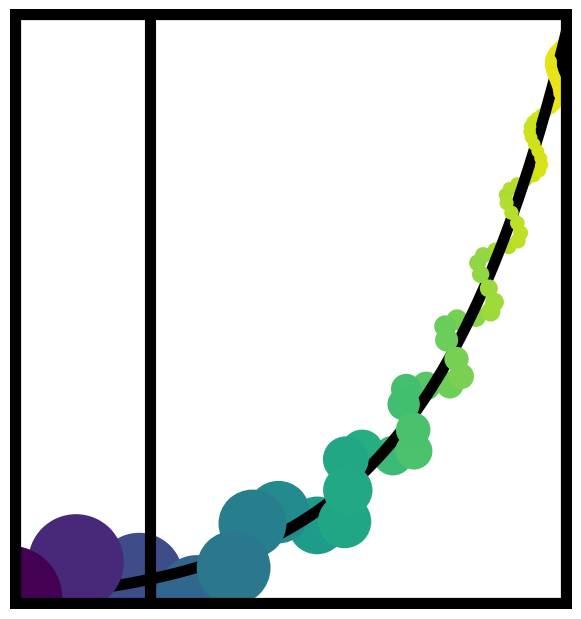

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.cm import get_cmap
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

# ----------  USER KNOBS  ------------------------------------
x_min, x_max     = -1.0, 3.0            # natural-space domain
n_backbone       = 3500                 # samples along exp curve

A_max, A_min     = 1.0, 0.2             # helix half-widths (L to R)
n_turns          = 9                    # whole sine waves
freq_pow         = 1.0                  # >1 would skew frequency rightward

n_beads          = 150
spacing_exp      = 4.0                  # bead-spacing bias  (<4 = looser right)
r_min_show, r_max = 0.20, 1.75          # bead radii (right ... left)
rad_beta         = 15.0                 # how fast radius shrinks

lw_back          = 8.0                  # stroke for backbone / axes / frame
lw_edge_max      = 0                    # bead edge on left
lw_edge_min      = 0.0                  # bead edge on right
edge_beta        = 5.0                  # bead outline fade

fig_side         = 6                    # square inches
out_base         = "chromatin_helix"    # basename for auto-save
# ------------------------------------------------------------


# 1)   backbone  y = e**x  in natural coordinates
x_nat = np.linspace(x_min, x_max, n_backbone)
y_nat = np.exp(x_nat)

# arc-length parameter s (natural space - gives nice bead spacing)
speed_nat = np.hypot(np.gradient(x_nat), np.gradient(y_nat))
s_nat     = np.concatenate([[0], cumulative_trapezoid(speed_nat, x_nat)])
L_nat     = s_nat[-1]
s_norm    = s_nat / L_nat

# 2)   horizontal stretch so the final canvas can be square
stretch = ((np.exp(x_max) + 0.4) - (-0.2)) / ((x_max - x_min) + 0.4)
X0, Y0  = stretch * x_nat, y_nat

# final axes / frame extents ( **exactly** reused everywhere )
x_left,  x_right  = stretch * x_min, stretch * x_max
y_bottom, y_top   = 0.0, np.exp(x_max)              # axes meet frame here

# 3)   normals of stretched exp curve
dX, dY = np.gradient(X0), np.gradient(Y0)
speed   = np.hypot(dX, dY)
Nx, Ny  = -dY / speed, dX / speed                    # unit normals

# 4)   helical spine  (amplitude tapers from A_max to A_min)
amp = A_min + (A_max - A_min) * (1 - s_norm)
phi = 2 * np.pi * n_turns * s_norm**freq_pow
offset = amp * np.sin(phi)
Xsp, Ysp = X0 + offset * Nx, Y0 + offset * Ny
ix, iy   = interp1d(s_nat, Xsp), interp1d(s_nat, Ysp)

# 5-a) bead positions (biased spacing)
p        = np.linspace(0, 1, n_beads)                     # 0 = far left ... 1 = far right
s_beads  = L_nat * (1 - (1 - p)**spacing_exp)
Xi, Yi   = ix(s_beads), iy(s_beads)

# 5-b) bead sizes & outlines
growth   = (np.exp(rad_beta * (1 - p)) - 1) / (np.exp(rad_beta) - 1)
radii    = r_min_show + (r_max - r_min_show) * growth
lw_edge  = lw_edge_min + (lw_edge_max - lw_edge_min) * np.exp(-edge_beta * p)

# 5-c) painter's depth (half-wave flip)
amp_b = A_min + (A_max - A_min) * (1 - s_beads / L_nat)
phi_b = 2 * np.pi * n_turns * (s_beads / L_nat)**freq_pow
depth  = amp_b * np.cos(phi_b)
back_ids  = np.where(depth < 0)[0][np.argsort(depth[depth < 0])]
front_ids = np.where(depth >= 0)[0][np.argsort(depth[depth >= 0])]

# 5-d) bead fill colours (Viridis: yellow to dark-blue)
x_norm = (Xi - Xi.min()) / (Xi.max() - Xi.min())
colors  = get_cmap('viridis')(x_norm)

# --------- plot - single Axes exactly the size of the frame -
fig, ax = plt.subplots(figsize=(fig_side, fig_side))

# beads behind
for i in back_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=1))

# backbone line (anti-aliased, opaque)
ax.plot(X0, Y0, color='black', lw=lw_back, zorder=2)

# beads in front
for i in front_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=3))

axis_z  = 4
frame_z = 5

# axes (share stroke with backbone & frame)
ax.plot([x_left, x_right], [0, 0],          lw=lw_back, color='black', zorder=axis_z)
ax.plot([0, 0],           [y_bottom, y_top], lw=lw_back, color='black', zorder=axis_z)

# frame rectangle exactly matches axes extents
ax.add_patch(Rectangle((x_left, y_bottom),
                       x_right - x_left, y_top - y_bottom,
                       fill=False, ec='black', lw=lw_back * 2,
                       capstyle='projecting', zorder=frame_z))

# occupy the whole figure; no extra borders in the saved file
fig.subplots_adjust(0, 0, 1, 1)
ax.set_xlim(x_left,  x_right)
ax.set_ylim(y_bottom, y_top)
ax.set_aspect('equal')
ax.axis('off')

# --------- auto-increment save-file helper -------------------
def next_fname(base: str, ext: str) -> str:
    n = 0
    while True:
        fn = f"{base}{'' if n == 0 else '_' + str(n)}.{ext}"
        if not os.path.exists(fn):
            return fn
        n += 1

png_name = next_fname(out_base, "png")
svg_name = next_fname(out_base, "svg")

fig.savefig(png_name, dpi=300, bbox_inches='tight', pad_inches=0)
fig.savefig(svg_name,            bbox_inches='tight', pad_inches=0)

plt.show()

/var/folders/p_/flb84jgs2_jbb5_gnn1645jw0000gn/T/ipykernel_15286/3284160097.py:81: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  vir      = get_cmap('viridis')


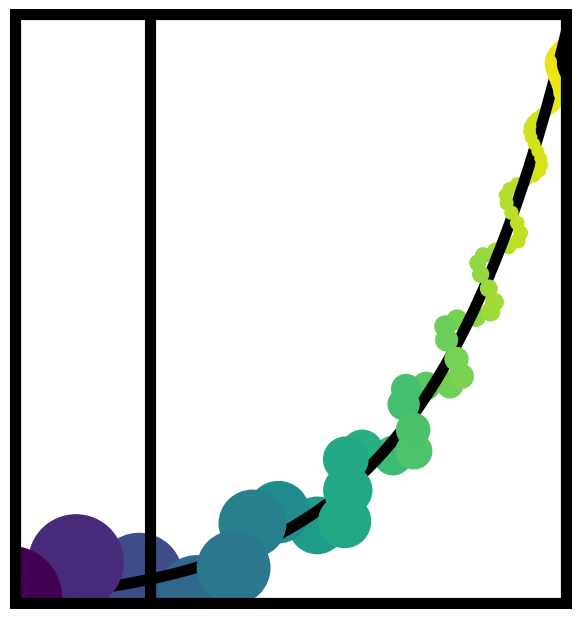

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.cm import get_cmap
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d

# ----------  USER KNOBS  ------------------------------------
x_min, x_max     = -1.0, 3.0            # natural-space domain
n_backbone       = 3500                 # samples along exp curve

A_max, A_min     = 1.0, 0.2             # helix half-widths (L to R)
n_turns          = 9                    # whole sine waves
freq_pow         = 1.0                  # >1 would skew frequency rightward

n_beads          = 150
spacing_exp      = 4.0                  # bead-spacing bias  (<4 = looser right)
r_min_show, r_max = 0.20, 1.75          # bead radii (right ... left)
rad_beta         = 15.0                 # how fast radius shrinks

lw_back          = 8.0                  # stroke for backbone / axes / frame
lw_edge_max      = 0                    # bead edge on left
lw_edge_min      = 0.0                  # bead edge on right
edge_beta        = 5.0                  # bead outline fade

fig_side         = 6                    # square inches
out_base         = "chromatin_helix"    # basename for auto-save
# ------------------------------------------------------------


# 1)   backbone  y = e**x  in natural coordinates
x_nat = np.linspace(x_min, x_max, n_backbone)
y_nat = np.exp(x_nat)

# arc-length parameter s (natural space - gives nice bead spacing)
speed_nat = np.hypot(np.gradient(x_nat), np.gradient(y_nat))
s_nat     = np.concatenate([[0], cumulative_trapezoid(speed_nat, x_nat)])
L_nat     = s_nat[-1]
s_norm    = s_nat / L_nat

# 2)   horizontal stretch so the final canvas can be square
stretch = ((np.exp(x_max) + 0.4) - (-0.2)) / ((x_max - x_min) + 0.4)
X0, Y0  = stretch * x_nat, y_nat

# final axes / frame extents ( **exactly** reused everywhere )
x_left,  x_right  = stretch * x_min, stretch * x_max
y_bottom, y_top   = 0.0, np.exp(x_max)              # axes meet frame here

# 3)   normals of stretched exp curve
dX, dY = np.gradient(X0), np.gradient(Y0)
speed   = np.hypot(dX, dY)
Nx, Ny  = -dY / speed, dX / speed                    # unit normals

# 4)   helical spine  (amplitude tapers from A_max to A_min)
amp = A_min + (A_max - A_min) * (1 - s_norm)
phi = 2 * np.pi * n_turns * s_norm**freq_pow
offset = amp * np.sin(phi)
Xsp, Ysp = X0 + offset * Nx, Y0 + offset * Ny
ix, iy   = interp1d(s_nat, Xsp), interp1d(s_nat, Ysp)

# 5-a) bead positions (biased spacing)
p        = np.linspace(0, 1, n_beads)                     # 0 = far left ... 1 = far right
s_beads  = L_nat * (1 - (1 - p)**spacing_exp)
Xi, Yi   = ix(s_beads), iy(s_beads)

# 5-b) bead sizes & outlines
growth   = (np.exp(rad_beta * (1 - p)) - 1) / (np.exp(rad_beta) - 1)
radii    = r_min_show + (r_max - r_min_show) * growth
lw_edge  = lw_edge_min + (lw_edge_max - lw_edge_min) * np.exp(-edge_beta * p)

# 5-c) painter's depth (half-wave flip)
amp_b = A_min + (A_max - A_min) * (1 - s_beads / L_nat)
phi_b = 2 * np.pi * n_turns * (s_beads / L_nat)**freq_pow
depth  = amp_b * np.cos(phi_b)
back_ids  = np.where(depth < 0)[0][np.argsort(depth[depth < 0])]
front_ids = np.where(depth >= 0)[0][np.argsort(depth[depth >= 0])]

# 5-d) bead fill colours (Viridis: yellow to dark-blue)
in_frame = (Xi >= x_left) & (Xi <= x_right)
vir      = get_cmap('viridis')

colors = np.empty((n_beads, 4))
rng     = np.ptp(Xi[in_frame])          
colors[in_frame]     = vir((Xi[in_frame] - Xi[in_frame].min()) / rng)
colors[Xi < x_left]  = vir(0.0)         # darkest left beads
colors[Xi > x_right] = vir(1.0)         # lightest right beads



# --------- plot single Axes exactly the size of the frame -
fig, ax = plt.subplots(figsize=(fig_side, fig_side))

# beads behind
for i in back_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=1))

# backbone line (anti-aliased, opaque)
ax.plot(X0, Y0, color='black', lw=lw_back, zorder=2)

# beads in front
for i in front_ids:
    ax.add_patch(Circle((Xi[i], Yi[i]), radii[i],
                        fc=colors[i], ec='black', lw=lw_edge[i], zorder=3))

axis_z  = 4
frame_z = 5

# axes (share stroke with backbone & frame)
ax.plot([x_left, x_right], [0, 0],          lw=lw_back, color='black', zorder=axis_z)
ax.plot([0, 0],           [y_bottom, y_top], lw=lw_back, color='black', zorder=axis_z)

# frame rectangle exactly matches axes extents
ax.add_patch(Rectangle((x_left, y_bottom),
                       x_right - x_left, y_top - y_bottom,
                       fill=False, ec='black', lw=lw_back * 2,
                       capstyle='projecting', zorder=frame_z))

# occupy the whole figure; no extra borders in the saved file
fig.subplots_adjust(0, 0, 1, 1)
ax.set_xlim(x_left,  x_right)
ax.set_ylim(y_bottom, y_top)
ax.set_aspect('equal')
ax.axis('off')

# --------- auto-increment save-file helper -------------------
def next_fname(base: str, ext: str) -> str:
    n = 0
    while True:
        fn = f"{base}{'' if n == 0 else '_' + str(n)}.{ext}"
        if not os.path.exists(fn):
            return fn
        n += 1

png_name = next_fname(out_base, "png")
svg_name = next_fname(out_base, "svg")

fig.savefig(png_name, dpi=300, bbox_inches='tight', pad_inches=0)
fig.savefig(svg_name,            bbox_inches='tight', pad_inches=0)

plt.show()